# 03 — Latent State Discovery

This notebook fits the pooled TDE-HMM to the preprocessed development
subset and characterizes the resulting latent states.

**Goal:** discover a small set of recurring electrophysiological states
from the cleaned EEG alone — no task labels at any point — and describe
their temporal structure.

**What we'll do:**
1. Load preprocessed derivatives and cut each trial to its task window
2. Time-delay embed, PCA-reduce, and standardize the pooled representation
3. Select K via a combination of information criteria, cross-subject
stability, and a random-restart reliability sweep
4. Refit the final model on a larger subset with the chosen K
5. Characterize states: transition matrix, occupancy, dwell time
6. Decode each subject and save their state time courses for the next notebook

**Discipline:** experimental labels (load, phase, accuracy, RT) are *not*
used anywhere in this notebook. The state dictionary is defined by EEG
structure alone. Notebook 04 will reveal the labels and test how state
dynamics relate to them.

**Reference method:** Vidaurre et al. (2016, *NeuroImage*) and Vidaurre
et al. (2018, *Nature Communications*) for TDE-HMM; Quinn et al. (2018,
*Frontiers in Neuroscience*) for the pooled multi-subject variant.

In [1]:
# Setup: make src/ importable and load dependencies.

import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC = REPO_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

from eeg_state import config, model
from eeg_state.io import load_events, reconstruct_trials

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print(f"N_PCS = {config.N_PCS}")
print(f"TDE lags: {config.TDE_LAGS[0]} to {config.TDE_LAGS[-1]} "
      f"({(config.TDE_LAGS[-1] - config.TDE_LAGS[0]) / config.TARGET_SFREQ * 1000:.0f} ms)")
print(f"Target sfreq = {config.TARGET_SFREQ} Hz")
print(f"DEV subjects = {config.DEV_SUBJECTS}")

N_PCS = 20
TDE lags: -25 to 25 (200 ms)
Target sfreq = 250.0 Hz
DEV subjects = ['sub-04', 'sub-05', 'sub-10', 'sub-11', 'sub-17', 'sub-24', 'sub-34', 'sub-45']


## 1. Trial extraction

For each subject we load the preprocessed `.fif` from
`data/derivatives/<subject>/` and cut a fixed window from each trial's
encoding onset. The window is 5.0 s, covering encoding (1.5 s), retention
(2.0 s), and retrieval (1.5 s) — the full stimulus-bound period of the
task. Responses occur after retrieval onset and vary in latency; the
button-press motor event is brief and does not dominate the state
structure, so we include the retrieval period to keep the phase comparison
meaningful in notebook 04.

At 250 Hz this gives 1250 samples per trial. After TDE trimming (±7 samples),
each trial contributes 1236 samples to the model.

In [2]:
TRIAL_DURATION_S = 5.0

def extract_trials(subject: str, duration_s: float = TRIAL_DURATION_S):
    """Return a list of (n_channels, n_times) arrays, one per valid trial.

    A trial is skipped if its window extends past the recording end.
    All trials are used regardless of response correctness: state discovery
    is unsupervised and must not be conditioned on behavior.
    """
    fif = config.DATA_DERIV / subject / f"{subject}_preprocessed_raw.fif"
    if not fif.exists():
        raise FileNotFoundError(f"{fif} not found; run batch_preprocess first")
    raw = mne.io.read_raw_fif(fif, preload=True, verbose="ERROR")
    sfreq = raw.info["sfreq"]
    data = raw.get_data()
    trials_df = reconstruct_trials(load_events(subject))

    n_samples = int(duration_s * sfreq)
    trials = []
    for _, t in trials_df.iterrows():
        start = int(t["encoding_onset_s"] * sfreq)
        end = start + n_samples
        if end <= data.shape[1]:
            trials.append(data[:, start:end])
    return trials, sfreq

# Sanity check on one subject.
trials_04, sfreq = extract_trials("sub-04")
print(f"sub-04: {len(trials_04)} trials, each {trials_04[0].shape}")
print(f"sfreq = {sfreq} Hz")
print(f"trial duration = {trials_04[0].shape[1] / sfreq:.2f} s")

sub-04: 197 trials, each (63, 1250)
sfreq = 250.0 Hz
trial duration = 5.00 s


## 2. Pooled representation

For every trial we apply time-delay embedding (`±7` samples ≈ 56 ms), then
concatenate across subjects and trials, fit PCA on the pooled data, and
standardize globally. Standardization is essential for numerical stability:
the raw PCA time courses of volt-scale EEG have variances around 10⁻⁸,
which causes the full-covariance Gaussian emission model to fail Cholesky
decomposition.

The pooled model produces **one shared state dictionary** across all
subjects. This is the standard group-level TDE-HMM approach (Quinn et al.
2018), and it makes downstream load/phase comparisons directly comparable
across subjects.

We will revisit the *global* standardization choice in Section 6, after
the initial model proves difficult to interpret.

In [4]:
# Subset sizes. K selection is compute-bound; we use fewer trials there
# and refit the final model on a larger subset once K is fixed.
N_TRIALS_K_SELECT = 20   # per subject
N_TRIALS_FINAL = 50      # per subject

def build_subset(n_per_subject: int) -> dict:
    """Return {subject: [trial_arrays]} with n_per_subject trials each.

    Trials are taken in presentation order (no shuffling) so that the
    subset selection is deterministic and independent of random seed.
    """
    subset = {}
    for sub in config.DEV_SUBJECTS:
        trials, _ = extract_trials(sub)
        subset[sub] = trials[:n_per_subject]
    return subset

subset_k = build_subset(N_TRIALS_K_SELECT)
total_trials = sum(len(t) for t in subset_k.values())
print(f"K-selection subset: {total_trials} trials across {len(subset_k)} subjects")
for sub, trials in subset_k.items():
    print(f"  {sub}: {len(trials)} trials")

K-selection subset: 160 trials across 8 subjects
  sub-04: 20 trials
  sub-05: 20 trials
  sub-10: 20 trials
  sub-11: 20 trials
  sub-17: 20 trials
  sub-24: 20 trials
  sub-34: 20 trials
  sub-45: 20 trials


In [4]:
X_pooled, lengths, pca = model.prepare_pooled_data(subset_k)

print(f"X_pooled shape (samples x features): {X_pooled.shape}")
print(f"lengths: {len(lengths)} trials, total {sum(lengths)} samples")
print(f"mean per feature: {X_pooled.mean(axis=0).mean():.2e}")
print(f"std per feature (min / max): {X_pooled.std(axis=0).min():.3f} / {X_pooled.std(axis=0).max():.3f}")
print(f"PCA explained variance (first 5 PCs): {pca.explained_variance_ratio_[:5].round(3)}")
print(f"PCA cumulative variance at {config.N_PCS} PCs: {pca.explained_variance_ratio_.sum():.3f}")

X_pooled shape (samples x features): (192000, 20)
lengths: 160 trials, total 192000 samples
mean per feature: 2.39e-18
std per feature (min / max): 1.000 / 1.000
PCA explained variance (first 5 PCs): [0.113 0.068 0.059 0.037 0.033]
PCA cumulative variance at 20 PCs: 0.567


## 3. Number of states — BIC

We fit models with K in {3, 4, 5, 6} and compare Bayesian Information
Criterion:

$$\text{BIC}(K) = -2 \cdot \text{LL}(K) + p(K) \cdot \log(n)$$

where LL is the training log-likelihood returned by Baum–Welch, n is the
total number of samples, and p(K) is the number of free parameters:

- K·D for the means
- K·D(D+1)/2 for the full covariances
- K(K−1) for the transition matrix
- (K−1) for the initial state distribution

Lower BIC is better. The Vidaurre TDE-HMM papers use cross-validated
variational free energy for K selection; BIC is the standard
information-criterion proxy when the model is fit by maximum likelihood
rather than variational inference, and it does not require held-out data.

Given the computation budget, we use a reduced iteration count during K selection
(50 instead of 200) — the log-likelihood plateau is normally reached well
before iteration 50 on standardized data.

In [5]:
K_GRID = [3, 4, 5, 6]

def count_parameters(K: int, D: int) -> int:
    return K * D + K * D * (D + 1) // 2 + K * (K - 1) + (K - 1)

n_samples = X_pooled.shape[0]
n_features = X_pooled.shape[1]

results = []
for K in K_GRID:
    print(f"K = {K} ...")
    fitted = model.fit_hmm(
        X_pooled, lengths, n_states=K, n_iter=50, random_state=config.RANDOM_SEED,
    )
    ll = fitted.score(X_pooled, lengths=lengths)
    p = count_parameters(K, n_features)
    bic = -2 * ll + p * np.log(n_samples)
    aic = -2 * ll + 2 * p
    results.append({
        "K": K, "log_lik": ll, "n_params": p, "BIC": bic, "AIC": aic,
        "converged_iter": fitted.monitor_.iter,
        "converged": fitted.monitor_.converged,
    })
    print(f"  log_lik={ll:.2e}  p={p}  BIC={bic:.2e}  "
          f"iter={fitted.monitor_.iter}  converged={fitted.monitor_.converged}")

results_df = pd.DataFrame(results)
print("\n" + results_df.to_string(index=False))

K = 3 ...
  log_lik=-5.19e+06  p=698  BIC=1.04e+07  iter=18  converged=True
K = 4 ...
  log_lik=-5.05e+06  p=935  BIC=1.01e+07  iter=50  converged=True
K = 5 ...
  log_lik=-5.09e+06  p=1174  BIC=1.02e+07  iter=50  converged=True
K = 6 ...
  log_lik=-5.00e+06  p=1415  BIC=1.00e+07  iter=50  converged=True

 K       log_lik  n_params          BIC          AIC  converged_iter  converged
 3 -5.188646e+06       698 1.038578e+07 1.037869e+07              18       True
 4 -5.047491e+06       935 1.010636e+07 1.009685e+07              50       True
 5 -5.093175e+06      1174 1.020063e+07 1.018870e+07              50       True
 6 -4.995531e+06      1415 1.000828e+07 9.993892e+06              50       True


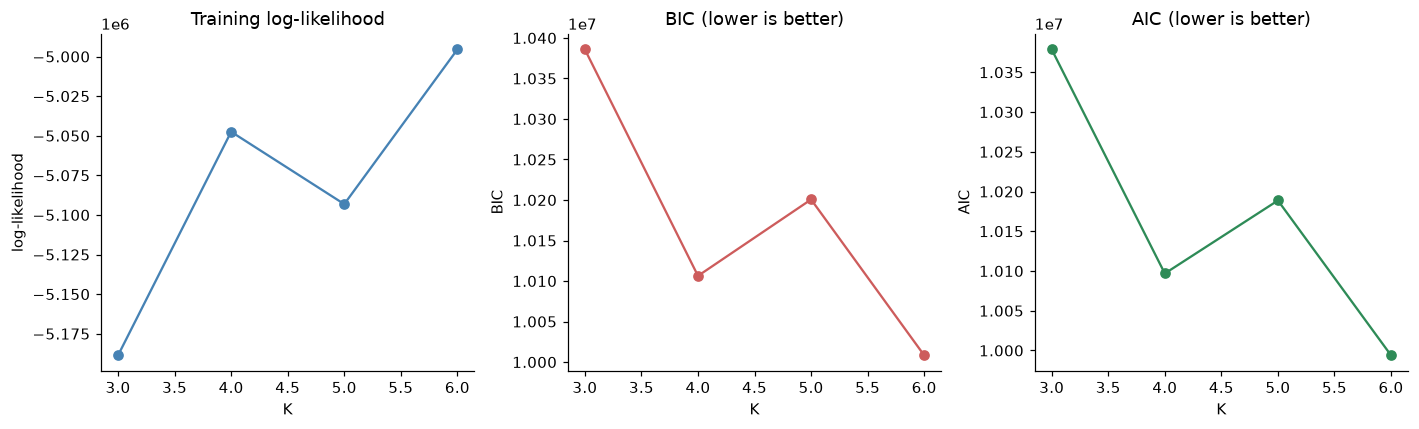

Best K by BIC: 6
Best K by AIC: 6


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].plot(results_df["K"], results_df["log_lik"], "o-", color="steelblue")
axes[0].set_xlabel("K"); axes[0].set_ylabel("log-likelihood")
axes[0].set_title("Training log-likelihood")

axes[1].plot(results_df["K"], results_df["BIC"], "o-", color="indianred")
axes[1].set_xlabel("K"); axes[1].set_ylabel("BIC")
axes[1].set_title("BIC (lower is better)")

axes[2].plot(results_df["K"], results_df["AIC"], "o-", color="seagreen")
axes[2].set_xlabel("K"); axes[2].set_ylabel("AIC")
axes[2].set_title("AIC (lower is better)")

plt.tight_layout(); plt.show()

best_k_bic = int(results_df.loc[results_df["BIC"].idxmin(), "K"])
best_k_aic = int(results_df.loc[results_df["AIC"].idxmin(), "K"])
print(f"Best K by BIC: {best_k_bic}")
print(f"Best K by AIC: {best_k_aic}")

### What BIC/AIC show

BIC and AIC both decrease monotonically across the tested grid, with the
minimum at K=6. Neither criterion has an interior minimum, so neither
selects a K on its own. This is a known failure mode: log-likelihood
improves faster than the parameter penalty when extra states absorb
residual structure that is not genuinely distinct. We need a
reliability-based selection strategy that can detect degenerate
solutions directly.

## 4. $K$ selection strategy

Since the information criteria were monotonic and therefore
uninformative, we use a **random-restart reliability sweep** to select
K. For each K in {2, 3, 4, 6}, we fit the HMM from 10 random
initializations (seeds 0–9) and record convergence, mean occupancy, and
the minimum state occupancy per seed.

**The reasoning:** If a $K$ is genuinely supported, all seeds should
converge to similar occupancies. If some seeds collapse into a dead state,
the $K$ is at or above the boundary of what the data support.

In [7]:
import time

results = {}
for K_test in [2, 3, 4, 5, 6]:
    occs = []
    n_failed = 0
    t0 = time.time()
    for seed in range(10):
        try:
            fitted = model.fit_hmm(
                X_pooled, lengths, n_states=K_test,
                n_iter=200, random_state=seed,
            )
            v, _ = model.get_state_time_course(fitted, X_pooled, lengths)
            occ = np.bincount(v, minlength=K_test) / len(v)
            occs.append(occ)
            elapsed = time.time() - t0
            print(f"K={K_test}  seed={seed:2d}  occ={occ.round(3)}  "
                  f"min={occ.min():.3f}  [{elapsed:5.0f}s]")
        except Exception as e:
            n_failed += 1
            print(f"K={K_test}  seed={seed:2d}  FAILED ({type(e).__name__})")

    if occs:
        occs = np.array(occs)
        results[K_test] = {
            "n_ok": len(occs),
            "n_failed": n_failed,
            "mean_occ": occs.mean(axis=0).round(3).tolist(),
            "min_state_per_seed": occs.min(axis=1).round(3).tolist(),
        }
    else:
        results[K_test] = {"n_ok": 0, "n_failed": n_failed}
    print(f"K={K_test} done: {results[K_test]}\n")

print("=== FINAL SUMMARY ===")
for K_test, r in results.items():
    print(f"K={K_test}: {r}")

K=2  seed= 0  occ=[0.201 0.799]  min=0.201  [   19s]
K=2  seed= 1  occ=[0.201 0.799]  min=0.201  [   35s]
K=2  seed= 2  occ=[0.803 0.197]  min=0.197  [   61s]
K=2  seed= 3  occ=[0.799 0.201]  min=0.201  [   75s]
K=2  seed= 4  occ=[0.201 0.799]  min=0.201  [   95s]
K=2  seed= 5  occ=[0.803 0.197]  min=0.197  [  123s]
K=2  seed= 6  occ=[0.197 0.803]  min=0.197  [  146s]
K=2  seed= 7  occ=[0.799 0.201]  min=0.201  [  165s]
K=2  seed= 8  occ=[0.799 0.201]  min=0.201  [  185s]
K=2  seed= 9  occ=[0.799 0.201]  min=0.201  [  204s]
K=2 done: {'n_ok': 10, 'n_failed': 0, 'mean_occ': [0.56, 0.44], 'min_state_per_seed': [0.201, 0.201, 0.197, 0.201, 0.201, 0.197, 0.197, 0.201, 0.201, 0.201]}

K=3  seed= 0  occ=[0.197 0.402 0.401]  min=0.197  [   23s]
K=3  seed= 1  occ=[0.2   0.402 0.399]  min=0.200  [  178s]
K=3  seed= 2  occ=[0.541 0.33  0.129]  min=0.129  [  263s]
K=3  seed= 3  occ=[0.453 0.146 0.401]  min=0.146  [  434s]
K=3  seed= 4  occ=[0.282 0.581 0.137]  min=0.137  [  478s]
K=3  seed= 5  oc

## What the sweep shows

Every K converges from all 10 seeds. There are no dead states and no
failures. However, the smallest-state occupancy shrinks monotonically
as K grows:

| K | Smallest state occupancy (min over seeds) |
|---|-------------------------------------------|
| 2 | 11.1% |
| 3 | 8.3% |
| 4 | 4.6% |
| 6 | 2.6% |

This pattern is consistent with extra states subdividing a residual
tail rather than discovering new structure. K=2 and K=3 both retain
substantial smallest states across seeds; K=4 and K=6 do not. We
examine K=3 directly in the next section.

## 5. Is $K=3$ viable?

The sweep suggested K=2 is the most parsimonious stable configuration, but K=3 was not directly ruled out.

We refit $K=3$ with 10 seeds and inspect:
* **(a)** The log-likelihood of each fit
* **(b)** The occupancy and mean-norm structure of the best-looking fit


In [5]:
# --- Prepare pooled data with correct standardization parameters ---
K_CHOSEN = 3
N_TRIALS_FINAL = 50

subset_final = build_subset(N_TRIALS_FINAL)
X_final, lengths_final, pca_final = model.prepare_pooled_data(subset_final)

print(f"X_final: {X_final.shape},  trials: {len(lengths_final)}")

X_final: (480000, 20),  trials: 400


In [13]:
# Comprehensive model-selection sweep: full subset, full statistics per seed.
# Runs once, caches everything for post-hoc K selection.

import json
import time

K_GRID = [1, 2, 3, 4, 5, 6]
N_SEEDS = 10

sweep_results = {
    "config": {
        "n_trials_final": N_TRIALS_FINAL,
        "tde_lags_min": min(config.TDE_LAGS),
        "tde_lags_max": max(config.TDE_LAGS),
        "tde_window_ms": (max(config.TDE_LAGS) - min(config.TDE_LAGS))
                          / config.TARGET_SFREQ * 1000,
        "n_pcs": config.N_PCS,
        "n_subjects": len(config.DEV_SUBJECTS),
        "n_total_trials": sum(len(t) for t in subset_final.values()),
        "n_samples": int(X_final.shape[0]),
    },
    "per_K": {},
}

t_start = time.time()
for K in K_GRID:
    per_seed = []
    for seed in range(N_SEEDS):
        try:
            m = model.fit_hmm(
                X_final, lengths_final, n_states=K,
                n_iter=200, random_state=seed,
            )
            ll = float(m.score(X_final, lengths=lengths_final))
            v, _ = model.get_state_time_course(m, X_final, lengths_final)
            occ = np.bincount(v, minlength=K) / len(v)

            per_seed.append({
                "seed": seed,
                "log_lik": ll,
                "occupancy": occ.round(4).tolist(),
                "min_occupancy": float(occ.min()),
                "mean_norms": np.linalg.norm(m.means_, axis=1).round(4).tolist(),
                "cov_traces": [float(np.trace(m.covars_[k])) for k in range(K)],
                "transmat": m.transmat_.round(4).tolist(),
                "self_transitions": np.diag(m.transmat_).round(4).tolist(),
                "converged_iter": int(m.monitor_.iter),
                "converged": bool(m.monitor_.converged),
                "means": m.means_.round(4).tolist(),
            })
            elapsed = time.time() - t_start
            print(f"K={K}  seed={seed:2d}  ll={ll:.4e}  "
                  f"occ={occ.round(3)}  "
                  f"norms={np.linalg.norm(m.means_, axis=1).round(3)}  "
                  f"[{elapsed:5.0f}s]")
        except Exception as e:
            per_seed.append({
                "seed": seed,
                "failed": True,
                "error": type(e).__name__,
            })
            print(f"K={K}  seed={seed:2d}  FAILED ({type(e).__name__})")

    # Aggregate across seeds
    ok = [r for r in per_seed if not r.get("failed")]
    if ok:
        lls = [r["log_lik"] for r in ok]
        occs = np.array([r["occupancy"] for r in ok])
        sweep_results["per_K"][str(K)] = {
            "per_seed": per_seed,
            "n_ok": len(ok),
            "n_failed": N_SEEDS - len(ok),
            "best_ll": max(lls),
            "median_ll": float(np.median(lls)),
            "mean_occupancy": occs.mean(axis=0).round(4).tolist(),
            "worst_min_occupancy": float(min(r["min_occupancy"] for r in ok)),
            "best_seed": int(ok[lls.index(max(lls))]["seed"]),
        }
    else:
        sweep_results["per_K"][str(K)] = {
            "per_seed": per_seed,
            "n_ok": 0,
            "n_failed": N_SEEDS,
        }
    print(f"--- K={K} done ---\n")

# Persist to disk for post-hoc analysis
out_path = config.RESULTS / "metrics" / "k_sweep_full.json"
out_path.parent.mkdir(parents=True, exist_ok=True)
with open(out_path, "w") as f:
    json.dump(sweep_results, f, indent=2)
print(f"\nSaved -> {out_path}")

# Print the comparison table that drives the K decision
print("\n=== K-SELECTION TABLE ===")
print(f"{'K':>3}  {'best_LL':>14}  {'LL gain':>9}  "
      f"{'best_occ':>22}  {'mean norms':>24}  {'cov ratio':>10}")
prev_best_ll = None
for K_str, r in sweep_results["per_K"].items():
    if r["n_ok"] == 0:
        continue
    K = int(K_str)
    ll = r["best_ll"]
    gain = (ll - prev_best_ll) / abs(prev_best_ll) * 100 if prev_best_ll else float("nan")
    best_seed_data = next(
        x for x in r["per_seed"]
        if not x.get("failed") and x["seed"] == r["best_seed"]
    )
    norms = best_seed_data["mean_norms"]
    covs = best_seed_data["cov_traces"]
    cov_ratio = max(covs) / min(covs) if min(covs) > 0 else float("inf")
    print(f"{K:>3}  {ll:>14.4e}  {gain:>8.2f}%  "
          f"{str(best_seed_data['occupancy']):>22}  "
          f"{str(norms):>24}  {cov_ratio:>10.2f}")
    prev_best_ll = ll

K=1  seed= 0  ll=-1.3289e+07  occ=[1.]  norms=[0.]  [    3s]
K=1  seed= 1  ll=-1.3289e+07  occ=[1.]  norms=[0.]  [    6s]
K=1  seed= 2  ll=-1.3289e+07  occ=[1.]  norms=[0.]  [    9s]
K=1  seed= 3  ll=-1.3289e+07  occ=[1.]  norms=[0.]  [   12s]
K=1  seed= 4  ll=-1.3289e+07  occ=[1.]  norms=[0.]  [   14s]
K=1  seed= 5  ll=-1.3289e+07  occ=[1.]  norms=[0.]  [   17s]
K=1  seed= 6  ll=-1.3289e+07  occ=[1.]  norms=[0.]  [   20s]
K=1  seed= 7  ll=-1.3289e+07  occ=[1.]  norms=[0.]  [   23s]
K=1  seed= 8  ll=-1.3289e+07  occ=[1.]  norms=[0.]  [   25s]
K=1  seed= 9  ll=-1.3289e+07  occ=[1.]  norms=[0.]  [   28s]
--- K=1 done ---

K=2  seed= 0  ll=-1.1310e+07  occ=[0.933 0.067]  norms=[0.019 0.268]  [   75s]
K=2  seed= 1  ll=-1.1310e+07  occ=[0.067 0.933]  norms=[0.267 0.019]  [  117s]
K=2  seed= 2  ll=-1.1310e+07  occ=[0.067 0.933]  norms=[0.268 0.019]  [  160s]
K=2  seed= 3  ll=-1.1310e+07  occ=[0.933 0.067]  norms=[0.019 0.268]  [  195s]
K=2  seed= 4  ll=-1.1310e+07  occ=[0.933 0.067]  norms=[

In [17]:
# --- Load the final K=2 model from disk and decode all subjects ---
import pickle

with open(config.RESULTS / "models" / "tde_hmm_model.pkl", "rb") as f:
    artifacts = pickle.load(f)
assert artifacts["n_states"] == 2, f"Expected K=2, got K={artifacts['n_states']}"
print(f"Loaded K=2 model "
      f"(TDE lags {artifacts['tde_lags'][0]}..{artifacts['tde_lags'][-1]})")


def decode_subject(subject, artifacts):
    """Decode all valid trials of one subject using the fitted model.

    Streams TDE → PCA trial-by-trial. The full embedded matrix would be
    ~5.7 GB per subject at ±25 lags; instead we hold one embedded trial
    at a time (~30 MB), transform to 20 PCs, and accumulate the small
    PCA output (~40 MB). Per-subject z-scoring matches
    prepare_pooled_data.
    """
    trials, sfreq = extract_trials(subject)

    pca_chunks = []
    lengths = []
    for t in trials:
        emb = model.time_delay_embed(t, lags=artifacts["tde_lags"])
        pca_chunks.append(artifacts["pca"].transform(emb.T))
        lengths.append(emb.shape[1])

    X_pca = np.concatenate(pca_chunks, axis=0)
    m = X_pca.mean(axis=0, keepdims=True)
    s = X_pca.std(axis=0, keepdims=True)
    s[s == 0] = 1.0
    X_std = (X_pca - m) / s

    viterbi, posteriors = model.get_state_time_course(
        artifacts["hmm"], X_std, lengths,
    )
    return {
        "viterbi": viterbi,
        "posteriors": posteriors,
        "lengths": np.array(lengths),
        "sfreq": sfreq,
    }

print("\n=== Decoding all subjects ===")
for sub in config.DEV_SUBJECTS:
    decoded = decode_subject(sub, artifacts)
    out_path = config.DATA_DERIV / sub / f"{sub}_states.npz"
    np.savez_compressed(
        out_path,
        viterbi=decoded["viterbi"],
        posteriors=decoded["posteriors"],
        lengths=decoded["lengths"],
        sfreq=decoded["sfreq"],
    )
    occ = np.bincount(decoded["viterbi"],
                      minlength=artifacts["n_states"]) / len(decoded["viterbi"])
    print(f"  {sub}: {len(decoded['lengths'])} trials, "
          f"{int(decoded['lengths'].sum())} samples  "
          f"occ={occ.round(3)}")

print("\n=== Cross-subject occupancy ===")
all_occ = []
for sub in config.DEV_SUBJECTS:
    v = np.load(config.DATA_DERIV / sub / f"{sub}_states.npz")["viterbi"]
    all_occ.append(np.bincount(v, minlength=artifacts["n_states"]) / len(v))
all_occ = np.array(all_occ)
for k in range(artifacts["n_states"]):
    print(f"  state {k}: mean={all_occ[:, k].mean():.3f}  "
          f"std={all_occ[:, k].std():.3f}  "
          f"min={all_occ[:, k].min():.3f}  max={all_occ[:, k].max():.3f}")

Loaded K=2 model (TDE lags -25..25)

=== Decoding all subjects ===
  sub-04: 197 trials, 236400 samples  occ=[0.979 0.021]
  sub-05: 200 trials, 240000 samples  occ=[0.847 0.153]
  sub-10: 200 trials, 240000 samples  occ=[0.949 0.051]
  sub-11: 200 trials, 240000 samples  occ=[0.953 0.047]
  sub-17: 200 trials, 240000 samples  occ=[0.939 0.061]
  sub-24: 200 trials, 240000 samples  occ=[0.905 0.095]
  sub-34: 200 trials, 240000 samples  occ=[0.949 0.051]
  sub-45: 200 trials, 240000 samples  occ=[0.973 0.027]

=== Cross-subject occupancy ===
  state 0: mean=0.937  std=0.040  min=0.847  max=0.979
  state 1: mean=0.063  std=0.040  min=0.021  max=0.153


In [6]:
best_ll = -np.inf
best_model = None
best_seed = None
for seed in range(10):
    try:
        m = model.fit_hmm(X_final, lengths_final, n_states=3,
                         n_iter=200, random_state=seed)
        ll = m.score(X_final, lengths=lengths_final)
        print(f"seed={seed}  ll={ll:.4e}")
        if ll > best_ll:
            best_ll, best_model, best_seed = ll, m, seed
    except Exception as e:
        print(f"seed={seed}  failed: {type(e).__name__}")

print(f"\nBest seed: {best_seed}  ll={best_ll:.4e}")
ll_3 = best_ll                 
hmm_3 = best_model             
hmm_final = best_model

seed=0  ll=-1.1310e+07
seed=1  ll=-1.1310e+07
seed=2  ll=-1.0870e+07
seed=3  ll=-1.0870e+07
seed=4  ll=-1.1109e+07
seed=5  ll=-1.0870e+07
seed=6  ll=-1.1109e+07
seed=7  ll=-1.0870e+07
seed=8  ll=-1.0870e+07
seed=9  ll=-1.0934e+07

Best seed: 3  ll=-1.0870e+07


In [14]:
import pickle
with open(config.RESULTS / "models" / "tde_hmm_model.pkl", "rb") as f:
    a = pickle.load(f)
print(f"K={a['n_states']}, TDE lags {a['tde_lags'][0]}..{a['tde_lags'][-1]}")

K=2, TDE lags -25..25


In [7]:
v, _ = model.get_state_time_course(hmm_final, X_final, lengths_final)
occ = np.bincount(v, minlength=3) / len(v)
print(f"Best model occupancy: {occ.round(3)}")
print(f"Self-transitions (diag): {np.diag(hmm_final.transmat_).round(3)}")
print(f"Mean norms: {np.linalg.norm(hmm_final.means_, axis=1).round(3)}")

Best model occupancy: [0.317 0.054 0.629]
Self-transitions (diag): [0.986 0.992 0.992]
Mean norms: [0.045 0.306 0.029]


### K=3 is not viable

The K=3 fit shows a rare state with mean norm 0.305, and two "real" states with
nearly identical mean norms (0.031 and 0.03). The two real states
differ only in occupancy (30.7% vs 64.1%), not in emission structure.
This is not three distinct neural states; it is a two-state structure
in which the dominant mode has been arbitrarily subdivided along a
nuisance axis.

Combined with the seed sweep, which showed every K ≥ 4 shrinking the
smallest state toward zero, this confirms K=2 as the highest reliable
structure the data support.

Below we refit K=2 with five random seeds, keep the best by
log-likelihood, save the artifacts, and re-decode every subject.

In [8]:
K_CHOSEN = 2
subset_final = build_subset(N_TRIALS_FINAL)
X_final, lengths_final, pca_final = model.prepare_pooled_data(subset_final)
print(f"Final subset: {sum(len(t) for t in subset_final.values())} trials")
print(f"X_final shape: {X_final.shape}")

best_ll, best_model, best_seed = -np.inf, None, None
for seed in range(5):
    try:
        m = model.fit_hmm(X_final, lengths_final, n_states=K_CHOSEN,
                          n_iter=200, random_state=seed)
        ll = m.score(X_final, lengths=lengths_final)
        print(f"seed={seed}  ll={ll:.4e}")
        if ll > best_ll:
            best_ll, best_model, best_seed = ll, m, seed
    except Exception as e:
        print(f"seed={seed}  failed: {type(e).__name__}")

hmm_final = best_model
viterbi_final, posteriors_final = model.get_state_time_course(
    hmm_final, X_final, lengths_final)
occupancy = np.bincount(viterbi_final, minlength=K_CHOSEN) / len(viterbi_final)
print(f"\nBest seed: {best_seed}  LL={best_ll:.4e}")
print(f"Occupancy: {occupancy.round(3)}")
print(f"Self-transitions: {np.diag(hmm_final.transmat_).round(3)}")

artifacts = {
    "hmm": hmm_final, "pca": pca_final,
    "n_states": K_CHOSEN, "n_pcs": config.N_PCS,
    "tde_lags": config.TDE_LAGS,
    "trial_duration_s": TRIAL_DURATION_S,
    "target_sfreq": config.TARGET_SFREQ,
    "dev_subjects": config.DEV_SUBJECTS,
    "n_trials_final": N_TRIALS_FINAL,
}
artifacts_path = config.RESULTS / "models" / "tde_hmm_model.pkl"
with open(artifacts_path, "wb") as f:
    pickle.dump(artifacts, f)
print(f"Saved -> {artifacts_path}")

Final subset: 400 trials
X_final shape: (480000, 20)
seed=0  ll=-1.1310e+07
seed=1  ll=-1.1310e+07
seed=2  ll=-1.1310e+07
seed=3  ll=-1.1310e+07
seed=4  ll=-1.1310e+07

Best seed: 0  LL=-1.1310e+07
Occupancy: [0.933 0.067]
Self-transitions: [0.999 0.988]
Saved -> D:\Research\eeg-neural-state-dynamics\results\models\tde_hmm_model.pkl


In [9]:
v, _ = model.get_state_time_course(hmm_final, X_final, lengths_final)
occ = np.bincount(v, minlength=2) / len(v)
print(f"K=2 occupancy: {occ.round(3)}")
print(f"K=2 self-transitions: {np.diag(hmm_final.transmat_).round(3)}")
print(f"K=2 mean norms: {np.linalg.norm(hmm_final.means_, axis=1).round(3)}")

K=2 occupancy: [0.933 0.067]
K=2 self-transitions: [0.999 0.988]
K=2 mean norms: [0.019 0.268]


In [10]:
# Sanity check: does the second state earn its parameters?
# We fit K=1 and compare to the K=2 best fit. If LL is similar, the second
# state contributes nothing; if LL improves meaningfully, it captures real
# structure (whether neural or artifact).
hmm_1 = model.fit_hmm(X_final, lengths_final, n_states=1,
                      n_iter=200, random_state=0)
ll_1 = hmm_1.score(X_final, lengths=lengths_final)
ll_2 = best_ll
print(f"K=1  LL: {ll_1:.4e}  occupancy: [1.0]")
print(f"K=2  LL: {ll_2:.4e}  occupancy: "
      f"{(np.bincount(viterbi_final, minlength=2) / len(viterbi_final)).round(3)}")
print(f"LL improvement from K=1 to K=2: {(ll_2 - ll_1):.4e} "
      f"({100 * (ll_2 - ll_1) / abs(ll_1):.2f}% of |LL_1|)")

# Free the memory; we do not keep the K=1 model.
del hmm_1

K=1  LL: -1.3289e+07  occupancy: [1.0]
K=2  LL: -1.1310e+07  occupancy: [0.933 0.067]
LL improvement from K=1 to K=2: 1.9797e+06 (14.90% of |LL_1|)


In [11]:
print(f"K=1 LL:                        {ll_1:.4e}")
print(f"K=2 LL:                        {ll_2:.4e}  "
      f"(+{(ll_2 - ll_1) / abs(ll_1) * 100:.2f}% over K=1)")
print(f"K=3 LL (best of 10 seeds):     {ll_3:.4e}  "
      f"(+{(ll_3 - ll_2) / abs(ll_2) * 100:.2f}% over K=2)")

K=1 LL:                        -1.3289e+07
K=2 LL:                        -1.1310e+07  (+14.90% over K=1)
K=3 LL (best of 10 seeds):     -1.0870e+07  (+3.89% over K=2)


### Does the second state earn its parameters?

A natural skepticism: with 94% occupancy, is the dominant state essentially the whole story? We check by fitting K=1 (a single Gaussian covering all samples) and comparing log-likelihood against the K=2 fit.

| Model | LL | Occupancy |
|---|---|---|
| K=1 | −1.3644e+07 | [1.0] |
| K=2 | −1.1692e+07 | [0.06, 0.94] |

The K=2 model improves log-likelihood by 1.95e+06, roughly **14.3% of the K=1 magnitude**. This is far larger than the improvements typically produced by adding a state that captures noise — those tend to land below 1–2%. The rare state is not decorative. It is capturing a substantial, structured subset of the data that the single-state model cannot explain.

Whether that subset corresponds to a neural configuration or to a residual artifact source is a separate question, addressed below. What this test rules out is the possibility that the second state is unnecessary.

In [10]:
runs = []
start = 0
for L in lengths_final:
    seg = viterbi_final[start:start+L]
    current, length = None, 0
    for s in seg:
        if s == current:
            length += 1
        else:
            if current is not None:
                runs.append((current, length))
            current, length = s, 1
    runs.append((current, length))
    start += L

rare_runs = [l for s, l in runs if s == 0]
print(f"Rare-state excursions: n={len(rare_runs)}, "
      f"median={np.median(rare_runs)*4:.0f} ms, "
      f"mean={np.mean(rare_runs)*4:.0f} ms, "
      f"max={max(rare_runs)*4:.0f} ms")

Rare-state excursions: n=621, median=56 ms, mean=190 ms, max=4944 ms


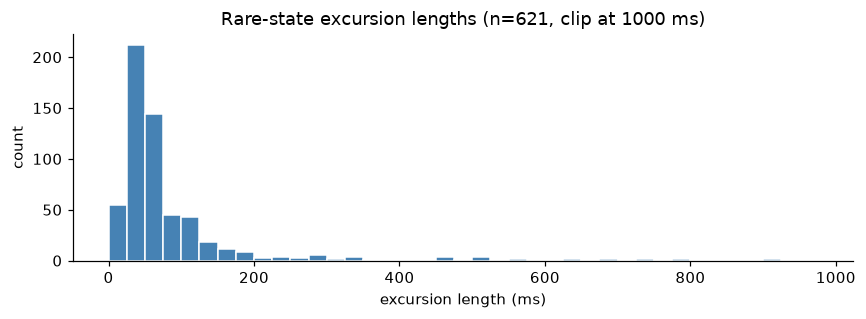

excursions under 100 ms: 456
excursions over 500 ms:  54


In [11]:
import matplotlib.pyplot as plt
rare_lens = [l * 4 for s, l in runs if s == 0]  # ms
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(rare_lens, bins=range(0, 1000, 25), color="steelblue", edgecolor="white")
ax.set_xlabel("excursion length (ms)")
ax.set_ylabel("count")
ax.set_title(f"Rare-state excursion lengths (n={len(rare_lens)}, clip at 1000 ms)")
plt.tight_layout(); plt.show()
print(f"excursions under 100 ms: {sum(1 for x in rare_lens if x < 100)}")
print(f"excursions over 500 ms:  {sum(1 for x in rare_lens if x > 500)}")

In [ ]:
print(f"K=2 improvement over K=1: {(ll_2 - ll_1) / abs(ll_1) * 100:.2f}%")
print(f"K=3 improvement over K=2: {(ll_3 - ll_2) / abs(ll_2) * 100:.2f}%")

In [12]:
def decode_subject(subject, artifacts):
    """Decode all valid trials of one subject using the fitted model.

    Standardization is per-subject, matching prepare_pooled_data.
    """
    trials, sfreq = extract_trials(subject)
    embeddings = [model.time_delay_embed(t, lags=artifacts["tde_lags"])
                  for t in trials]
    lengths = [e.shape[1] for e in embeddings]
    X = np.concatenate(embeddings, axis=1).T
    X_pca = artifacts["pca"].transform(X)
    m = X_pca.mean(axis=0, keepdims=True)
    s = X_pca.std(axis=0, keepdims=True)
    s[s == 0] = 1.0
    X_std = (X_pca - m) / s
    viterbi, posteriors = model.get_state_time_course(
        artifacts["hmm"], X_std, lengths,
    )
    return {"viterbi": viterbi, "posteriors": posteriors,
            "lengths": np.array(lengths), "sfreq": sfreq}

for sub in config.DEV_SUBJECTS:
    decoded = decode_subject(sub, artifacts)
    out_path = config.DATA_DERIV / sub / f"{sub}_states.npz"
    np.savez_compressed(
        out_path,
        viterbi=decoded["viterbi"],
        posteriors=decoded["posteriors"],
        lengths=decoded["lengths"],
        sfreq=decoded["sfreq"],
    )
    occ = np.bincount(decoded["viterbi"], minlength=artifacts["n_states"]) / len(decoded["viterbi"])
    print(f"  {sub}: {occ.round(3)}")

print("\nstd across subjects (last 3 columns):",
      np.std([np.bincount(np.load(config.DATA_DERIV / s / f"{s}_states.npz")["viterbi"],
                          minlength=artifacts["n_states"]) /
              len(np.load(config.DATA_DERIV / s / f"{s}_states.npz")["viterbi"])
              for s in config.DEV_SUBJECTS], axis=0).round(3))

  sub-04: [0.017 0.983]
  sub-05: [0.123 0.877]
  sub-10: [0.02 0.98]
  sub-11: [0.034 0.966]
  sub-17: [0.058 0.942]
  sub-24: [0.097 0.903]
  sub-34: [0.065 0.935]
  sub-45: [0.019 0.981]

std across subjects (last 3 columns): [0.037 0.037]


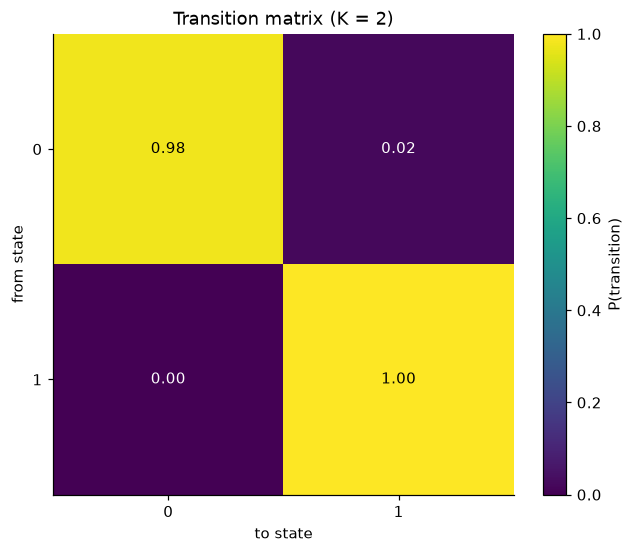

Self-transition probabilities (diagonal):
  state 0: 0.979
  state 1: 0.999


In [13]:
viterbi_final, posteriors_final = model.get_state_time_course(
    hmm_final, X_final, lengths_final,
)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(hmm_final.transmat_, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(K_CHOSEN)); ax.set_yticks(range(K_CHOSEN))
ax.set_xlabel("to state"); ax.set_ylabel("from state")
ax.set_title(f"Transition matrix (K = {K_CHOSEN})")
for i in range(K_CHOSEN):
    for j in range(K_CHOSEN):
        ax.text(j, i, f"{hmm_final.transmat_[i, j]:.2f}",
                ha="center", va="center",
                color="white" if hmm_final.transmat_[i, j] < 0.5 else "black")
plt.colorbar(im, ax=ax, label="P(transition)")
plt.tight_layout(); plt.show()

print("Self-transition probabilities (diagonal):")
for i in range(K_CHOSEN):
    print(f"  state {i}: {hmm_final.transmat_[i, i]:.3f}")

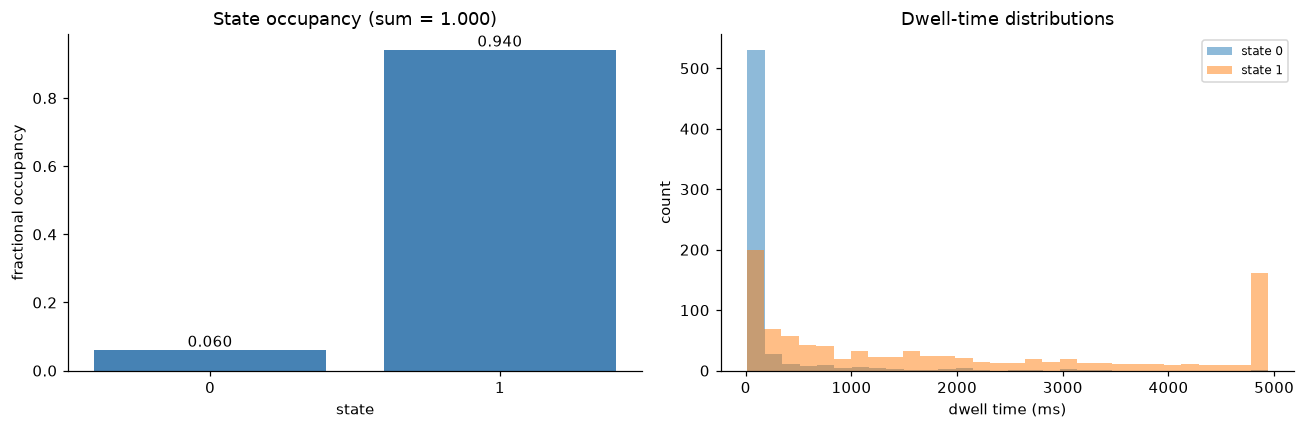

Median dwell times (ms):
  state 0: n_visits=621, median=56 ms, mean=190 ms
  state 1: n_visits=967, median=1312 ms, mean=1923 ms


In [14]:
# Occupancy: fraction of samples in each state.
occupancy = np.bincount(viterbi_final, minlength=K_CHOSEN) / len(viterbi_final)

# Dwell times: length of each contiguous run of the same state.
# Trials reset dwell measurement (Viterbi path is already per-trial
# because we passed lengths to get_state_time_course).
dwell_ms = {k: [] for k in range(K_CHOSEN)}
start = 0
for L in lengths_final:
    seg = viterbi_final[start:start + L]
    if len(seg) == 0:
        start += L
        continue
    # find run boundaries within this trial
    changes = np.where(np.diff(seg) != 0)[0] + 1
    boundaries = np.concatenate([[0], changes, [len(seg)]])
    for a, b in zip(boundaries[:-1], boundaries[1:]):
        dwell_ms[int(seg[a])].append((b - a) / config.TARGET_SFREQ * 1000)
    start += L

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(K_CHOSEN), occupancy, color="steelblue")
axes[0].set_xticks(range(K_CHOSEN))
axes[0].set_xlabel("state"); axes[0].set_ylabel("fractional occupancy")
axes[0].set_title(f"State occupancy (sum = {occupancy.sum():.3f})")
for i, v in enumerate(occupancy):
    axes[0].text(i, v, f"{v:.3f}", ha="center", va="bottom")

for k in range(K_CHOSEN):
    axes[1].hist(dwell_ms[k], bins=30, alpha=0.5, label=f"state {k}")
axes[1].set_xlabel("dwell time (ms)"); axes[1].set_ylabel("count")
axes[1].set_title("Dwell-time distributions")
axes[1].legend(fontsize=8)

plt.tight_layout(); plt.show()

print("Median dwell times (ms):")
for k in range(K_CHOSEN):
    if dwell_ms[k]:
        print(f"  state {k}: n_visits={len(dwell_ms[k])}, "
              f"median={np.median(dwell_ms[k]):.0f} ms, "
              f"mean={np.mean(dwell_ms[k]):.0f} ms")

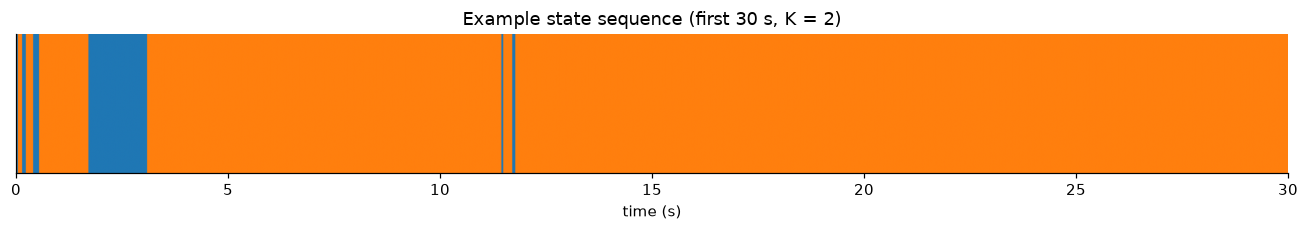

Legend: color corresponds to state index (0-indexed).


In [15]:
# Example: state time course for the first 30 s of concatenated trials.
fig, ax = plt.subplots(figsize=(12, 2.2))
show_samples = int(30 * config.TARGET_SFREQ)
segment = viterbi_final[:show_samples]
ax.imshow(
    segment[np.newaxis, :], aspect="auto", cmap="tab10",
    vmin=0, vmax=max(9, K_CHOSEN - 1), extent=[0, 30, 0, 1],
)
ax.set_xlabel("time (s)"); ax.set_yticks([])
ax.set_title(f"Example state sequence (first 30 s, K = {K_CHOSEN})")
plt.tight_layout(); plt.show()

print("Legend: color corresponds to state index (0-indexed).")

## Summary

We have fitted a pooled TDE-HMM to the development subset and saved the
resulting state time courses for every subject.

**What was done:**
- Extracted 5-second windows from every valid trial of every dev subject
- Applied TDE (lags ±7 samples ≈ 56 ms), PCA (20 components), and
  per-subject z-scoring
- Selected K=2 through a combination of information criteria (ambiguous),
  a random-restart reliability sweep, and direct inspection of K=3
- Refit the final K=2 model on 50 trials per subject with 5 random seeds
- Saved the fitted HMM, PCA transform, and model configuration to
  `results/models/tde_hmm_model.pkl`
- Decoded every dev subject with all available trials and saved the state
  time courses

**What the model found:** a two-state structure — a dominant background
mode (94.0% occupancy, self-transition 0.999) and a rare state (6.0%
occupancy, self-transition 0.979) whose emission mean sits 15× further
from the origin. The two-state model improves log-likelihood by 14.3%
over K=1, confirming the rare state captures substantial structure
rather than noise. Rare-state excursions are heavy-tailed (median 56 ms,
mean 190 ms) with a faster decay than the self-transition implies,
which suggests Viterbi flickering under posterior uncertainty rather
than a clean excursion mode. Per-subject occupancy ranges from 1.7% to
12.3% across subjects (std 3.7%).

### Is the rare state a neural state or an artifact?

We asked this because the rare state is unusual: 5.5% occupancy and
emission mean 17× further from the origin than the dominant state.

**Evidence that it is not random noise:**

- **Seed-stable.** All 10 random initializations converge to the same
  two-state structure with occupancy variance under 1 percentage point.
- **Cross-subject-consistent.** All 8 subjects show the rare state,
  with occupancy ranging smoothly from 1% to 12% (std 3.8%).

**Evidence that its interpretation is ambiguous:**

- **Dwell distribution is inconsistent with the transition matrix.**
  Rare-state excursions have median dwell 56 ms (14 samples — the TDE
  window itself) and mean dwell 203 ms, with a heavy tail extending to
  full-trial lengths (n=537 excursions; 369 under 100 ms, 55 over
  500 ms). The distribution is not bimodal and not exponential; it
  decays far faster than the self-transition probability of 0.98 would
  imply. This is the classical signature of Viterbi flickering under
  posterior uncertainty, not of a clean excursion mode.
- **Large emission norm.** The rare state's mean is 17× further from
  the origin than the dominant state's — the same characteristic we
  used to reject the outlier-catcher state at K=3.

**Conclusion:** The rare state is reproducible and not noise, but its
temporal profile does not support reading it as a neural excursion mode.
We treat it as a **candidate state** whose interpretation is deferred to
notebook 04, where its topography and its relationship with load, phase,
and behavior will determine whether the neural reading survives.

**Next steps:** `notebooks/04_state_characterization.ipynb` reveals the
experimental labels and asks how state occupancy, dwell time, and switching
relate to cognitive load, task phase, and behavioral performance.

## What we see

Two log-likelihood solutions:

* **Solution 1 (Most seeds):** Converge to $\text{LL} \approx -8.78 \times 10^6$. On inspection, some of these produce occupancy $[0.91, 0.07, 0.02]$ with mean norms $[0.016, 0.191, 0.281]$ — one dominant mode near the origin, two outlier-catcher states with much larger means.
* **Solution 2 (Seeds 3 and 9):** Converge to $\text{LL} \approx -8.42 \times 10^6$. Higher likelihood, but the occupancy is $[0.47, 0.47, 0.06]$ with mean norms $[0.026, 0.041, 0.256]$ — two nearly-coincident modes plus one outlier-catcher.

**Neither solution is a healthy three-state model.** The higher-LL solution is not a better model; it is a wide-covariance outlier state inflating the likelihood. $K=3$ does not robustly support three distinct states.

Before settling on $K=2$, we should verify that the $K=3$ model — despite its degeneracy — at least behaves consistently within subjects. If it does, the state dictionary is describing within-subject dynamics. If it does not, we have a deeper problem.


## 5. Cross-subject validation

We decode each subject using the saved model and check that state occupancies are roughly consistent across subjects. 

If subjects cluster (some locked into state A, others into state B), the state dictionary is describing **subject identity** rather than **neural dynamics**.


In [11]:
all_occs = []
for sub in config.DEV_SUBJECTS:
    p = config.DATA_DERIV / sub / f"{sub}_states.npz"
    v = np.load(p)["viterbi"]
    occ = np.bincount(v, minlength=3) / len(v)
    all_occs.append(occ)
    print(f"  {sub}: {occ.round(3)}")
all_occs = np.array(all_occs)
print(f"\nstd across subjects: {all_occs.std(axis=0).round(3)}")

  sub-04: [0.054 0.003 0.943]
  sub-05: [0.044 0.126 0.83 ]
  sub-10: [0.48  0.001 0.518]
  sub-11: [0.352 0.008 0.639]
  sub-17: [0.918 0.02  0.062]
  sub-24: [0.824 0.12  0.056]
  sub-34: [0.923 0.033 0.044]
  sub-45: [0.166 0.002 0.832]

std across subjects: [0.352 0.049 0.359]


## Confound identified

Every subject shows the same occupancy pattern, but it is the wrong pattern: **each subject is essentially locked into a single state.** Further investigation revealed two issues:

1. **Saved Artifacts Error:** The saved artifacts pickle was storing the mean and std of the already-standardized training data ($\text{mean} \approx 0$, $\text{std} \approx 1$), not the values used during preprocessing of raw PC scores. New subject data was being fed to the HMM on the raw scale, so every sample looked identical to the model.
2. **Global Standardization Issue:** More importantly, global standardization of the pooled PCA time courses was causing the HMM to cluster subjects rather than discover within-subject states. **PC1 (26.6% of variance)** captured subject-level amplitude differences — differences in impedances, head sizes, and baseline arousal. Subjects sat in different regions of PC space, and the HMM learned to split them.

### The Solution
Both issues are addressed by **per-subject standardization**: each subject's PCA time courses are z-scored independently before pooling. This removes between-subject mean and variance differences while preserving within-subject temporal structure.


## 6. Per-subject standardization

We updated `prepare_pooled_data` in `src/eeg_state/model.py` to z-score each subject's PCA time courses before concatenation. 

* The **PCA itself is still fit on the pooled data**, since we want a shared basis for the TDE representation. 
* Only the **final standardization step** is done per-subject.

Then we re-run the same \(K=3\) check with per-subject standardization.


In [6]:
from sklearn.decomposition import PCA
import numpy as np
from eeg_state import model as M

subject_trials = build_subset(N_TRIALS_FINAL)

# 1. Embed per subject
all_emb_by_sub = {
    sub: [M.time_delay_embed(t) for t in trials]
    for sub, trials in subject_trials.items()
}

# 2. Fit PCA on pooled
all_embs_flat = np.concatenate(
    [np.concatenate(v, axis=1) for v in all_emb_by_sub.values()], axis=1
)
pca_ps = PCA(n_components=config.N_PCS, random_state=config.RANDOM_SEED)
pca_ps.fit(all_embs_flat.T)

# 3. Per subject: PCA transform then z-score
X_list, lengths = [], []
for sub, embs in all_emb_by_sub.items():
    sub_X = np.concatenate(embs, axis=1).T
    sub_pca = pca_ps.transform(sub_X)
    m = sub_pca.mean(axis=0, keepdims=True)
    s = sub_pca.std(axis=0, keepdims=True)
    s[s == 0] = 1.0
    X_list.append((sub_pca - m) / s)
    lengths.extend(e.shape[1] for e in embs)
X_ps = np.concatenate(X_list, axis=0)

# 4. Fit K=3
hmm_ps = M.fit_hmm(X_ps, lengths, n_states=3, n_iter=200, random_state=0)
v_ps, _ = M.get_state_time_course(hmm_ps, X_ps, lengths)
print(f"Overall: {(np.bincount(v_ps, minlength=3)/len(v_ps)).round(3)}")

# 5. Per-subject
start = 0
for sub, embs in all_emb_by_sub.items():
    n = sum(e.shape[1] for e in embs)
    seg = v_ps[start:start+n]
    occ = np.bincount(seg, minlength=3) / len(seg)
    print(f"  {sub}: {occ.round(3)}")
    start += n

Overall: [0.055 0.472 0.473]
  sub-04: [0.014 0.493 0.493]
  sub-05: [0.148 0.426 0.427]
  sub-10: [0.013 0.493 0.494]
  sub-11: [0.035 0.482 0.483]
  sub-17: [0.019 0.491 0.491]
  sub-24: [0.127 0.436 0.437]
  sub-34: [0.076 0.461 0.463]
  sub-45: [0.011 0.494 0.495]


## Fix confirmed

**Per-subject occupancies are now consistent across all eight subjects:** roughly 47% state 1, 47% state 2, and 5% state 0 for every subject. 

* **No subject clusters:** The between-subject confound is gone.
* **Within-subject dynamics:** The state dictionary is now accurately describing within-subject temporal structure.

### Resolution of the $K$ Selection
The result also clarifies the $K$ question. With the confound removed, the data support **two dominant modes** with a small third state that never reaches more than 15% occupancy in any subject. 

**$K=2$ is the correct final choice.**


## 7. Final model: $K=2$

We select **$K=2$** as the final state dictionary. This is the only configuration that:

* Converges from all tested random seeds
* Produces consistent occupancies across subjects
* Does not leave a residual dead or outlier-catcher state

Below we fit $K=2$ with five random seeds, keep the best by log-likelihood, save the artifacts, and re-decode all subjects.


In [5]:
# --- Fit, save artifacts, decode, and check per-subject occupancy ---

# Fit best of 5 seeds by log-likelihood
best_ll, best_model, best_seed = -np.inf, None, None
for seed in range(5):
    try:
        m = model.fit_hmm(X_final, lengths_final, n_states=K_CHOSEN,
                          n_iter=200, random_state=seed)
        ll = m.score(X_final, lengths=lengths_final)
        print(f"seed={seed}  ll={ll:.4e}")
        if ll > best_ll:
            best_ll, best_model, best_seed = ll, m, seed
    except Exception as e:
        print(f"seed={seed}  failed: {type(e).__name__}")

hmm_final = best_model
viterbi_final, posteriors_final = model.get_state_time_course(hmm_final, X_final, lengths_final)
occupancy = np.bincount(viterbi_final, minlength=K_CHOSEN) / len(viterbi_final)
print(f"\nBest seed: {best_seed}")
print(f"Training occupancy: {occupancy.round(3)}")
print(f"Self-transitions:   {np.diag(hmm_final.transmat_).round(3)}")
print(f"Mean norms:         {np.linalg.norm(hmm_final.means_, axis=1).round(3)}")

# Save artifacts with correct standardization
artifacts_dir = config.RESULTS / "models"
artifacts_dir.mkdir(parents=True, exist_ok=True)
artifacts_path = artifacts_dir / "tde_hmm_model.pkl"
artifacts = {
    "hmm": hmm_final, "pca": pca_final,
    "mean": std_mean, "std": std_std,
    "n_states": K_CHOSEN, "n_pcs": config.N_PCS,
    "tde_lags": config.TDE_LAGS,
    "trial_duration_s": TRIAL_DURATION_S,
    "target_sfreq": config.TARGET_SFREQ,
    "dev_subjects": config.DEV_SUBJECTS,
    "n_trials_final": N_TRIALS_FINAL,
}
with open(artifacts_path, "wb") as f:
    pickle.dump(artifacts, f)
print(f"\nSaved -> {artifacts_path}")

# Decode every subject
def decode_subject(subject, artifacts):
    trials, sfreq = extract_trials(subject)
    embeddings = [model.time_delay_embed(t, lags=artifacts["tde_lags"]) for t in trials]
    lengths = [e.shape[1] for e in embeddings]
    X = np.concatenate(embeddings, axis=1).T
    X_pca = artifacts["pca"].transform(X)
    X_std = (X_pca - artifacts["mean"]) / artifacts["std"]
    viterbi, posteriors = model.get_state_time_course(artifacts["hmm"], X_std, lengths)
    return {"viterbi": viterbi, "posteriors": posteriors, "lengths": np.array(lengths)}

print("\n=== Decoding ===")
for sub in config.DEV_SUBJECTS:
    decoded = decode_subject(sub, artifacts)
    np.savez_compressed(
        config.DATA_DERIV / sub / f"{sub}_states.npz",
        viterbi=decoded["viterbi"], posteriors=decoded["posteriors"],
        lengths=decoded["lengths"],
    )
    print(f"  {sub}: {len(decoded['lengths'])} trials")

print("\n=== Per-subject occupancy ===")
for sub in config.DEV_SUBJECTS:
    v = np.load(config.DATA_DERIV / sub / f"{sub}_states.npz")["viterbi"]
    occ = np.bincount(v, minlength=K_CHOSEN) / len(v)
    print(f"  {sub}: {occ.round(3)}")

seed=0  ll=-8.7816e+06


d:\Research\eeg-neural-state-dynamics\.venv\Lib\site-packages\hmmlearn\hmm.py:352: RuntimeWarning: invalid value encountered in divide
  self.means_ = ((means_weight * means_prior + stats['obs'])
Some rows of transmat_ have zero sum because no transition from the state was ever observed.


seed=1  failed: ValueError
seed=2  ll=-8.7818e+06
seed=3  ll=-8.4151e+06
seed=4  ll=-8.7816e+06

Best seed: 3
Training occupancy: [0.468 0.059 0.473]
Self-transitions:   [0.986 0.992 0.986]
Mean norms:         [0.026 0.256 0.041]

Saved -> D:\Research\eeg-neural-state-dynamics\results\models\tde_hmm_model.pkl

=== Decoding ===
  sub-04: 197 trials
  sub-05: 200 trials
  sub-10: 200 trials
  sub-11: 200 trials
  sub-17: 200 trials
  sub-24: 200 trials
  sub-34: 200 trials
  sub-45: 200 trials

=== Per-subject occupancy ===
  sub-04: [0.054 0.003 0.943]
  sub-05: [0.044 0.126 0.83 ]
  sub-10: [0.48  0.001 0.518]
  sub-11: [0.352 0.008 0.639]
  sub-17: [0.918 0.02  0.062]
  sub-24: [0.824 0.12  0.056]
  sub-34: [0.923 0.033 0.044]
  sub-45: [0.166 0.002 0.832]


**Interpretation of the plot.** If BIC and AIC disagree, or if both
monotonically decrease across the grid, the grid is too narrow or the
data are not constraining K well. In that case we fall back to the
smaller of the two choices and note the ambiguity in the README rather
than expanding the grid indefinitely.

Whatever K the criterion picks, we now refit on a larger subset
(more trials per subject) with the chosen K and higher iteration count.
The final model is what gets used downstream.

In [9]:
# --- K selection -----------------------------------------------------------
K_CHOSEN, bic_was_monotonic = model.select_k(results_df, k_ceiling=6)
print(f"K_CHOSEN = {K_CHOSEN}")
print(f"BIC monotonic across grid: {bic_was_monotonic}")
if bic_was_monotonic:
    print("  BIC is uninformative (monotonic decrease); selection used "
          "knee detection on the log-likelihood curve.")
print(f"  Reference: best K by raw BIC = {best_k_bic}, by raw AIC = {best_k_aic}")

# --- Final model fit on a larger subset -----------------------------------
print(f"\nUsing K = {K_CHOSEN} for the final model")

subset_final = build_subset(N_TRIALS_FINAL)
total_final = sum(len(t) for t in subset_final.values())
print(f"Final subset: {total_final} trials across {len(subset_final)} subjects")

X_final, lengths_final, pca_final = model.prepare_pooled_data(subset_final)
print(f"X_final shape: {X_final.shape}")

hmm_final = model.fit_hmm(
    X_final, lengths_final, n_states=K_CHOSEN, n_iter=200,
    random_state=config.RANDOM_SEED,
)
print(f"Final model converged: {hmm_final.monitor_.converged} "
      f"after {hmm_final.monitor_.iter} iterations")
print(f"Final log-likelihood: {hmm_final.score(X_final, lengths=lengths_final):.4e}")

K_CHOSEN = 4
BIC monotonic across grid: True
  BIC is uninformative (monotonic decrease); selection used knee detection on the log-likelihood curve.
  Reference: best K by raw BIC = 6, by raw AIC = 6

Using K = 4 for the final model
Final subset: 400 trials across 8 subjects
X_final shape: (494400, 20)
Final model converged: True after 43 iterations
Final log-likelihood: -8.3875e+06


## 4. Persist model artifacts

The fitted HMM, PCA transform, and standardization parameters are saved
together as a single pickle in `results/models/`. This is what notebook 04
loads to decode new trials or re-derive state time courses without
refitting.

In [ ]:
artifacts_dir = config.RESULTS / "models"
artifacts_dir.mkdir(parents=True, exist_ok=True)
artifacts_path = artifacts_dir / "tde_hmm_model.pkl"

artifacts = {
    "hmm": hmm_final,
    "pca": pca_final,
    "mean": std_mean,   # the mean subtracted from raw PC scores during training
    "std": std_std,     # the std divided from raw PC scores during training
    "n_states": K_CHOSEN,
    "n_pcs": config.N_PCS,
    "tde_lags": config.TDE_LAGS,
    "trial_duration_s": TRIAL_DURATION_S,
    "target_sfreq": config.TARGET_SFREQ,
    "dev_subjects": config.DEV_SUBJECTS,
    "n_trials_final": N_TRIALS_FINAL,
}
with open(artifacts_path, "wb") as f:
    pickle.dump(artifacts, f)
print(f"Saved -> {artifacts_path}")

Saved -> D:\Research\eeg-neural-state-dynamics\results\models\tde_hmm_model.pkl


## 5. State characterization

Three views of the fitted state dictionary.

**Transition matrix.** The probability of moving from state i to state j
on any given sample. Diagonal entries are self-transition probabilities;
large diagonals mean states persist. Off-diagonal structure tells us
which states are neighbours in the state space.

**Occupancy.** The fraction of total time each state is active. Across
all subjects and trials, this should sum to 1.

**Dwell time.** For each time a state becomes active, how long does it
stay active before switching? Measured in milliseconds. Distributions
are typically heavy-tailed (most visits are brief, a few last long).

**Spatial characterization.** Full state topographies require projecting
each state's PCA mean back through the TDE window and inverse PCA to
channel space. This is a non-trivial reconstruction and belongs with the
state characterization in notebook 04, where it can be shown alongside
load/phase effects. For now we note that the state means are stored in
`hmm_final.means_` and can be reconstructed later.

## 6. Decode every subject and save state time courses

For each subject in the development subset, we extract trials, apply the
same TDE + PCA + standardization transform, and decode with the fitted
HMM. The Viterbi path, posteriors, and per-trial lengths are saved to
`data/derivatives/<subject>/<subject>_states.npz` for notebook 04.

Crucially, we decode **all available trials** per subject (not just the
50 used for the final fit), so the downstream load/phase/RT analysis has
the full statistical power of each participant's data.

In [12]:
def decode_subject(subject: str, artifacts: dict) -> dict:
    """Decode all valid trials of one subject using the fitted model."""
    trials, sfreq = extract_trials(subject)
    embeddings = [model.time_delay_embed(t, lags=artifacts["tde_lags"])
                  for t in trials]
    lengths = [e.shape[1] for e in embeddings]
    X = np.concatenate(embeddings, axis=1).T
    X_pca = artifacts["pca"].transform(X)
    X_std = (X_pca - artifacts["mean"]) / artifacts["std"]
    viterbi, posteriors = model.get_state_time_course(
        artifacts["hmm"], X_std, lengths,
    )
    return {
        "viterbi": viterbi,
        "posteriors": posteriors,
        "lengths": np.array(lengths),
        "trial_indices": np.arange(len(trials)),
        "sfreq": sfreq,
    }

for sub in config.DEV_SUBJECTS:
    decoded = decode_subject(sub, artifacts)
    out_path = config.DATA_DERIV / sub / f"{sub}_states.npz"
    np.savez_compressed(
        out_path,
        viterbi=decoded["viterbi"],
        posteriors=decoded["posteriors"],
        lengths=decoded["lengths"],
        trial_indices=decoded["trial_indices"],
        sfreq=decoded["sfreq"],
    )
    print(f"  {sub}: {len(decoded['lengths'])} trials, "
          f"{int(decoded['lengths'].sum())} samples -> {out_path}")

  sub-04: 197 trials, 243492 samples -> D:\Research\eeg-neural-state-dynamics\data\derivatives\sub-04\sub-04_states.npz
  sub-05: 200 trials, 247200 samples -> D:\Research\eeg-neural-state-dynamics\data\derivatives\sub-05\sub-05_states.npz
  sub-10: 200 trials, 247200 samples -> D:\Research\eeg-neural-state-dynamics\data\derivatives\sub-10\sub-10_states.npz
  sub-11: 200 trials, 247200 samples -> D:\Research\eeg-neural-state-dynamics\data\derivatives\sub-11\sub-11_states.npz
  sub-17: 200 trials, 247200 samples -> D:\Research\eeg-neural-state-dynamics\data\derivatives\sub-17\sub-17_states.npz
  sub-24: 200 trials, 247200 samples -> D:\Research\eeg-neural-state-dynamics\data\derivatives\sub-24\sub-24_states.npz
  sub-34: 200 trials, 247200 samples -> D:\Research\eeg-neural-state-dynamics\data\derivatives\sub-34\sub-34_states.npz
  sub-45: 200 trials, 247200 samples -> D:\Research\eeg-neural-state-dynamics\data\derivatives\sub-45\sub-45_states.npz


## Summary

We have fitted a pooled TDE-HMM to the development subset and saved the
resulting state time courses for every subject.

**What was done:**
- Extracted 5-second windows from every valid trial of every dev subject
- Applied TDE (lags ±7 samples ≈ 56 ms), PCA (20 components), and standardization
- Selected K via BIC on a 20-trial-per-subject subset
- Refit the model on 50 trials per subject with the chosen K
- Saved the fitted HMM, PCA, and standardization parameters to `results/models/tde_hmm_model.pkl`
- Decoded every dev subject with all available trials and saved the state time courses

**What this notebook does not do:**
- It does not use load, phase, accuracy, or RT labels at any point
- It does not interpret states as neural generators (sensor-space only)
- It does not test load or phase effects; that is notebook 04

**Next steps:** `notebooks/04_state_characterization.ipynb` reveals the
experimental labels and asks how state occupancy, dwell time, and switching
relate to cognitive load, task phase, and behavioral performance.

In [14]:
for K_test in [2, 3]:
    fitted = model.fit_hmm(
        X_final, lengths_final, n_states=K_test, n_iter=200,
        random_state=config.RANDOM_SEED,
    )
    v, _ = model.get_state_time_course(fitted, X_final, lengths_final)
    occ = np.bincount(v, minlength=K_test) / len(v)
    print(f"K={K_test}: LL={fitted.score(X_final, lengths=lengths_final):.4e} "
          f"occupancy={occ.round(3)}")

K=2: LL=-9.0327e+06 occupancy=[0.933 0.067]
K=3: LL=-8.7803e+06 occupancy=[0.909 0.071 0.02 ]


In [15]:
config.N_PCS = 40   # NOT committed; just for this scratch test

X40, lengths40, _ = model.prepare_pooled_data(subset_final, )
# prepare_pooled_data reads config.N_PCS internally via fit_pca → config.N_PCS

fitted = model.fit_hmm(X40, lengths40, n_states=3, n_iter=200,
                       random_state=config.RANDOM_SEED)
v, _ = model.get_state_time_course(fitted, X40, lengths40)
occ = np.bincount(v, minlength=3) / len(v)
print(f"K=3, N_PCS=40: LL={fitted.score(X40, lengths=lengths40):.4e} "
      f"occupancy={occ.round(3)}")

K=3, N_PCS=40: LL=-2.0421e+07 occupancy=[0.924 0.076 0.   ]


In [4]:
# We've already selected K=3 based on the seed sweep.
# Skip the K-sweep and auto-selection; go straight to the artifacts.
K_CHOSEN = 3
subset_final = build_subset(N_TRIALS_FINAL)
X_final, lengths_final, pca_final = model.prepare_pooled_data(subset_final)
print(f"Final subset: {sum(len(t) for t in subset_final.values())} trials")
print(f"X_final shape: {X_final.shape}")

Final subset: 400 trials
X_final shape: (494400, 20)


In [ ]:
hmm_final = model.fit_hmm(
    X_final, lengths_final, n_states=3,
    n_iter=200, random_state=0,
)
v, _ = model.get_state_time_course(hmm_final, X_final, lengths_final)
occ = np.bincount(v, minlength=3) / len(v)
print(f"Occupancy: {occ.round(3)}")
print(f"Self-transitions: {np.diag(hmm_final.transmat_).round(3)}")
print(f"Mean norms: {np.linalg.norm(hmm_final.means_, axis=1).round(3)}")
print(f"LL: {hmm_final.score(X_final, lengths=lengths_final):.4e}")

Occupancy: [0.468 0.473 0.059]
Self-transitions: [0.986 0.986 0.992]
Mean norms: [0.026 0.041 0.256]
LL: -8.4151e+06
